<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/MachineLearningT1_Bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

He so chan: 542.7480527754583
He so goc: 19.527820370541825
MSE: 26147.980548680156
R2: 0.9756909156275313
Gia du doan nha 100m2: 2495.53 trieu VND


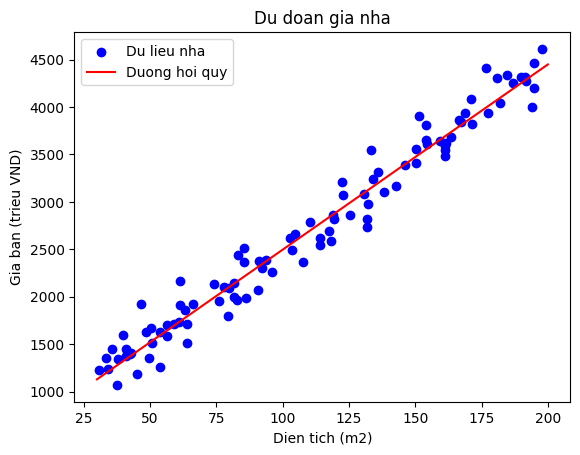

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tao 100 can nha voi dien tich tu 30 den 200 m2
np.random.seed(42)
X = np.random.uniform(30, 200, (100, 1))

# Gia nha (trieu VND), co them nhieu ngau nhien
y = 500 + 20 * X.ravel() + np.random.normal(0, 200, 100)

# 2. Chia du lieu: 80% hoc, 20% kiem tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Tao va huan luyen mo hinh
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Du doan va danh gia
y_pred = model.predict(X_test)

print("He so chan:", model.intercept_)
print("He so goc:", model.coef_[0])
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

# 5. Du doan can nha 100m2
gia = model.predict([[100]])[0]
print("Gia du doan nha 100m2:", round(gia, 2), "trieu VND")

# 6. Ve bieu do
plt.scatter(X, y, color="blue", label="Du lieu nha")
x_line = np.linspace(30, 200, 100).reshape(-1, 1)
plt.plot(x_line, model.predict(x_line),
         color="red", label="Duong hoi quy")
plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia ban (trieu VND)")
plt.title("Du doan gia nha")
plt.legend()
plt.show()



So mau=100, Do nhieu=200, MSE=34349.69, R2=0.9626
So mau=100, Do nhieu=500, MSE=214685.58, R2=0.7917
So mau=500, Do nhieu=200, MSE=37498.25, R2=0.9657
So mau=500, Do nhieu=500, MSE=234364.05, R2=0.8189


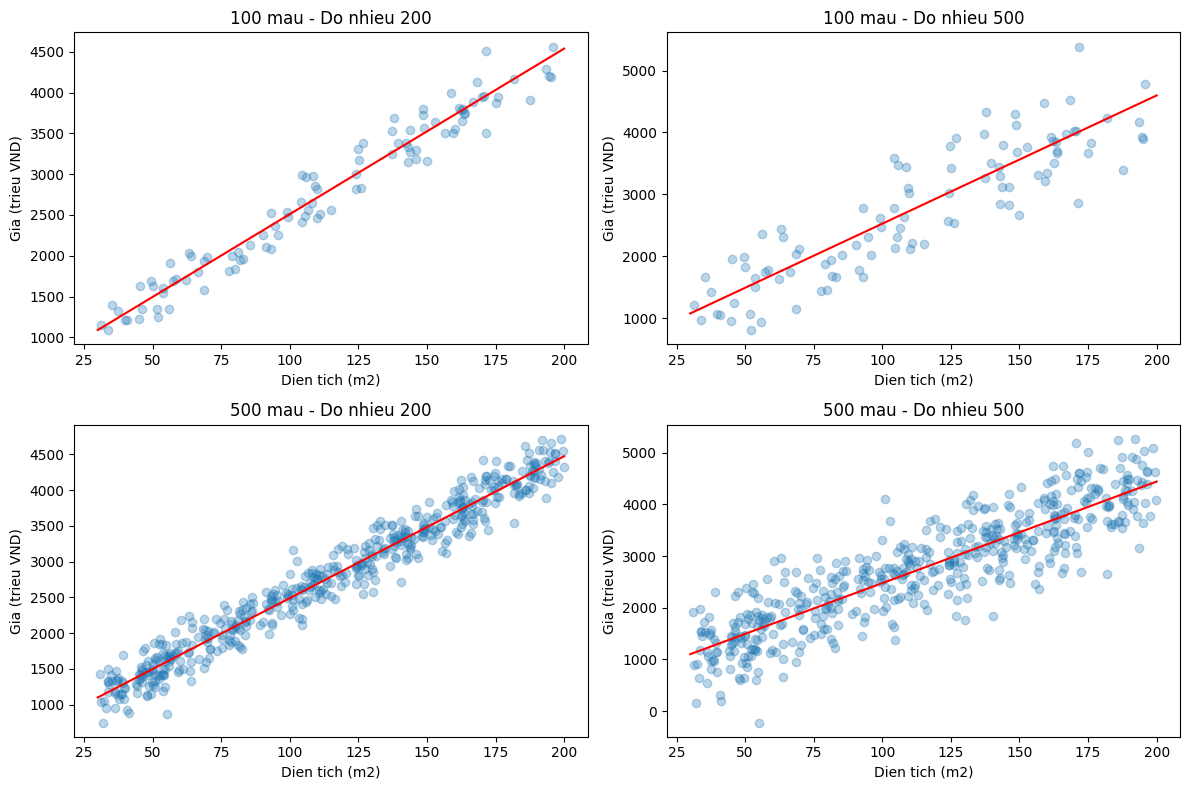

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Thu nghiem 100 va 500 mau, voi do nhieu 200 va 500
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, n, noise in zip(
    axes.ravel(),
    [100, 100, 500, 500],
    [200, 500, 200, 500]
):
    rng = np.random.default_rng(42)
    X = rng.uniform(30, 200, (n, 1))
    y = 500 + 20 * X.ravel() + rng.normal(0, noise, n)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"So mau={n}, Do nhieu={noise}, MSE={mse:.2f}, R2={r2:.4f}")

    x_line = np.linspace(30, 200, 100).reshape(-1, 1)
    ax.scatter(X, y, alpha=0.3)
    ax.plot(x_line, model.predict(x_line), color="red")
    ax.set_title(f"{n} mau - Do nhieu {noise}")
    ax.set_xlabel("Dien tich (m2)")
    ax.set_ylabel("Gia (trieu VND)")

plt.tight_layout()
plt.show()


In [4]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

rng = np.random.default_rng(42)
n = 300

# Tao du lieu nhieu thuoc tinh
data = pd.DataFrame({
    "DienTich": rng.uniform(30, 200, n),
    "SoPhongNgu": rng.integers(1, 6, n),
    "TuoiNha": rng.integers(0, 30, n)
})

# Gia nha phu thuoc vao 3 thuoc tinh
data["GiaBan"] = (
    500
    + 20 * data["DienTich"]
    + 150 * data["SoPhongNgu"]
    - 15 * data["TuoiNha"]
    + rng.normal(0, 200, n)
)

print("5 dong du lieu:")
print(data.head())

X = data[["DienTich", "SoPhongNgu", "TuoiNha"]]
y = data["GiaBan"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nHe so chan:", model.intercept_)
print("He so cac thuoc tinh:")
print(pd.Series(model.coef_, index=X.columns))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

# Du doan nha 100m2, 3 phong ngu, 5 nam tuoi
nha_moi = pd.DataFrame({
    "DienTich": [100],
    "SoPhongNgu": [3],
    "TuoiNha": [5]
})

print("Gia du doan:", model.predict(nha_moi)[0], "trieu VND")


5 dong du lieu:
     DienTich  SoPhongNgu  TuoiNha       GiaBan
0  161.572528           4        0  4581.040562
1  104.609335           4        1  3126.683228
2  175.961646           4        6  4601.923795
3  148.552565           1       26  2749.066906
4   46.010149           5       13  1743.933451

He so chan: 509.19166555128095
He so cac thuoc tinh:
DienTich       19.943173
SoPhongNgu    149.101793
TuoiNha       -15.932011
dtype: float64
MSE: 42683.87511480777
R2: 0.9593480544462507
Gia du doan: 2871.1543232594854 trieu VND
